# 04 Advanced Model, Hybrid and Final Evaluation
Week 4 deliverables: an advanced model (latent factors and a justified hybrid), a fair model comparison, beyond-accuracy measures and interpretation.

**Why a hybrid.** In notebook 03, item-item CF scored *below* 3-day recency-weighted popularity on accuracy, yet it covered 73% of the catalogue against 14 items. Each approach captures something different, and the exclusion of already-bought items ignores repeat purchases. This notebook therefore (1) measures what customers actually buy next, (2) builds five components, and (3) fuses them with weights tuned on validation.

**Protocol.** All tuning uses the validation block and models are fitted on the training period only. The test block is used once at the end, after refitting on training plus validation with the tuned settings.

Run notebooks 02 and 03 first.

In [1]:
import itertools, json, pickle, sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse

from src import config, data_audit as da, prepare as prep, evaluation as ev, recommender as rec, latent, hybrid as hy

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 100)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(config.IMAGES_DIR / name, dpi=150)
    plt.show()

## 1. Load data and define two evaluation tracks

In [2]:
articles = da.load_articles()
articles_by_id = articles.set_index("article_id")
prepared = prep.load_prepared()
exp = prep.build_experiment(prepared, articles)
K, N_ITEMS = config.TOP_K, len(exp.items)
train_m, val_m = exp.train_matrix, exp.val_matrix

# Track 1 "discovery": recommend items the customer has NOT bought before; truth = first-time purchases only
val_new = (val_m - val_m.multiply(train_m)).tocsr()
val_new.eliminate_zeros()
# Track 2 "all purchases": any purchase counts, including re-buying; this is the business objective
users_all = prep.users_with_interactions(val_m)
users_new = prep.users_with_interactions(val_new)
print(f"users {len(exp.users):,} | items {N_ITEMS:,} | validation users: all purchases {len(users_all):,}, "
      f"with a first-time purchase {len(users_new):,}")

def evaluate(recs, truth, users):
    return ev.evaluate_topk(recs, truth, users, exp.item_user_share, N_ITEMS, exp.category_of_item)

users 45,078 | items 11,916 | validation users: all purchases 6,698, with a first-time purchase 6,495


## 2. What do customers buy next?
Before choosing models, classify every validation purchase by what the customer had bought in training: the *same article* again, *another colour variant of a product* they had bought, or a *product they never bought*. This shows which kinds of candidate a recommender must be able to produce.

In [3]:
val_df = exp.split.val
u = exp.users.get_indexer(val_df["customer_id"].cat.categories)[val_df["customer_id"].cat.codes.to_numpy()]
i = exp.items.get_indexer(val_df["article_id"])
product_code = pd.factorize(exp.product_of_item)[0]
pack = lambda users, things: users.astype(np.int64) * 2**31 + things
tu, ti = train_m.nonzero()
same_article = np.isin(pack(u, i), np.unique(pack(tu, ti)))
same_product = ~same_article & np.isin(pack(u, product_code[i]), np.unique(pack(tu, product_code[ti])))
composition = pd.Series({"same article bought before": same_article.mean(),
                         "other colour/variant of a product bought before": same_product.mean(),
                         "product never bought by this customer": (~same_article & ~same_product).mean()})
display(composition.rename("share of validation purchases").to_frame())

,share of validation purchases
same article bought before,0.0498
other colour/variant of a product bought before,0.0574
product never bought by this customer,0.8928


**Reading this.** If a meaningful share of purchases are repeats or variants, then excluding already-bought items (as in notebook 03) removes real hits, and a *repurchase* component is justified. The share of never-bought products shows how much room there is for discovery, which is where collaborative filtering and content similarity matter.

## 3. Tune the individual components

### 3a. Popularity half-life (items the customer has not bought)

In [4]:
base_scores = {h: prep.popularity_scores(exp.split.train, exp.items, h) for h in (None, *config.HALF_LIVES_DAYS)}
rows = []
for h, s in base_scores.items():
    recs = prep.recommend_popular(s, train_m, users_new, K)
    rows.append({"half-life (d)": h if h else np.nan, **evaluate(recs, val_new, users_new)})
pop_grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False)
display(pop_grid.head(5))
pop_hl = pop_grid.iloc[0]["half-life (d)"]
pop_hl = None if np.isnan(pop_hl) else float(pop_hl)
pop_ranking = np.argsort(-base_scores[pop_hl], kind="stable")
print("Selected popularity half-life:", pop_hl)

,half-life (d),Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
2,3.0000,0.0079,0.0368,0.0206,0.0012,8.2019,0.0073,0.5008,"6,495.0000"
1,1.0000,0.0078,0.0374,0.0205,0.0012,9.1753,0.0044,0.6993,"6,495.0000"
3,5.0000,0.0077,0.0357,0.0202,0.0012,8.1843,0.0073,0.5091,"6,495.0000"
4,7.0000,0.0075,0.0342,0.0195,0.0012,8.0640,0.0075,0.5985,"6,495.0000"
5,14.0000,0.0065,0.0280,0.0169,0.0012,6.9109,0.0124,0.6125,"6,495.0000"


Selected popularity half-life: 3.0


### 3b. Item-item collaborative filtering (re-tuned on the discovery track)

In [5]:
knn_history = {hl: (train_m if hl is None else
                    prep.build_interaction_matrix(exp.split.train, exp.users, exp.items, "recency", half_life_days=hl))
               for hl in config.KNN_HISTORY_HALF_LIVES}
rows, tables = [], {}
for shrink in config.KNN_SHRINK:
    tables[shrink] = rec.build_neighbour_table(train_m, k_max=max(config.KNN_NEIGHBOURS), shrink=shrink)
    for k in config.KNN_NEIGHBOURS:
        model = rec.ItemKNN(tables[shrink], k)
        for hl, hist in knn_history.items():
            recs = model.recommend(hist, users_new, K, pop_ranking)
            rows.append({"shrink": shrink, "neighbours": k, "history half-life (d)": hl if hl else np.nan,
                         **evaluate(recs, val_new, users_new)})
knn_grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False).reset_index(drop=True)
display(knn_grid.head(8))
b = knn_grid.iloc[0]
knn_choice = dict(shrink=float(b["shrink"]), k=int(b["neighbours"]),
                  hl=None if np.isnan(b["history half-life (d)"]) else float(b["history half-life (d)"]))
print("Selected:", knn_choice)

,shrink,neighbours,history half-life (d),Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
0,20.0000,50,28.0000,0.0052,0.0258,0.0176,0.7210,8.9055,0.0031,0.4074,"6,495.0000"
1,20.0000,100,28.0000,0.0053,0.0257,0.0176,0.7174,8.8678,0.0032,0.4074,"6,495.0000"
2,20.0000,20,28.0000,0.0053,0.0261,0.0176,0.7210,8.9483,0.0030,0.4099,"6,495.0000"
3,20.0000,200,28.0000,0.0052,0.0255,0.0176,0.7181,8.8381,0.0034,0.4098,"6,495.0000"
4,20.0000,200,14.0000,0.0052,0.0254,0.0174,0.7680,8.9872,0.0030,0.4142,"6,495.0000"
5,20.0000,100,14.0000,0.0051,0.0250,0.0173,0.7647,9.0044,0.0030,0.4117,"6,495.0000"
6,20.0000,20,14.0000,0.0051,0.0248,0.0171,0.7617,9.0677,0.0028,0.4107,"6,495.0000"
7,20.0000,50,14.0000,0.0051,0.0248,0.0171,0.7638,9.0345,0.0029,0.4097,"6,495.0000"


Selected: {'shrink': 20.0, 'k': 50, 'hl': 28.0}


### 3c. Latent factors (PureSVD)
Truncated SVD of the user-item matrix. Item-count damping scales each column by `count ** -damping` so popular items do not dominate the factors.

In [6]:
rows, svd_models = [], {}
for damping in config.SVD_ITEM_DAMPING:
    for hl in config.SVD_HISTORY_HALF_LIVES:
        hist = train_m if hl is None else prep.build_interaction_matrix(
            exp.split.train, exp.users, exp.items, "recency", half_life_days=hl)
        t0 = time.time()
        factors = latent.fit_puresvd(hist, max_factors=max(config.SVD_FACTORS), item_damping=damping,
                                     seed=config.RANDOM_SEED)
        print(f"damping={damping}, history half-life={hl}: SVD fitted in {time.time() - t0:.0f}s")
        for nf in config.SVD_FACTORS:
            model = latent.LatentFactorRecommender(factors, nf)
            recs = model.recommend(hist, users_new, K)
            rows.append({"damping": damping, "history half-life (d)": hl if hl else np.nan, "factors": nf,
                         **evaluate(recs, val_new, users_new)})
svd_grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False).reset_index(drop=True)
display(svd_grid.head(8))
b = svd_grid.iloc[0]
svd_choice = dict(damping=float(b["damping"]), factors=int(b["factors"]),
                  hl=None if np.isnan(b["history half-life (d)"]) else float(b["history half-life (d)"]))
print("Selected:", svd_choice)

damping=0.0, history half-life=None: SVD fitted in 14s
damping=0.0, history half-life=28: SVD fitted in 10s
damping=0.5, history half-life=None: SVD fitted in 12s
damping=0.5, history half-life=28: SVD fitted in 10s


,damping,history half-life (d),factors,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
0,0.0000,28.0000,32,0.0051,0.0224,0.0154,0.0309,7.7961,0.0063,0.5245,"6,495.0000"
1,0.0000,28.0000,128,0.0048,0.0216,0.0143,0.0817,8.4042,0.0043,0.5666,"6,495.0000"
2,0.0000,28.0000,64,0.0047,0.0212,0.0141,0.0508,8.0504,0.0053,0.5332,"6,495.0000"
3,0.5000,28.0000,32,0.0045,0.0214,0.0129,0.0240,10.3897,0.0009,0.6222,"6,495.0000"
4,0.0000,NaN,64,0.0041,0.0191,0.0123,0.0522,7.1633,0.0075,0.4717,"6,495.0000"
5,0.5000,28.0000,64,0.0041,0.0195,0.0121,0.0400,10.4074,0.0008,0.6101,"6,495.0000"
6,0.0000,NaN,128,0.0038,0.0183,0.0118,0.0822,7.4476,0.0062,0.5021,"6,495.0000"
7,0.0000,NaN,32,0.0042,0.0186,0.0114,0.0313,6.9101,0.0089,0.4833,"6,495.0000"


Selected: {'damping': 0.0, 'factors': 32, 'hl': 28.0}


### 3d. Content similarity
Items are described by TF-IDF of their name and description plus one-hot product attributes (type, colour, department, section, ...). A customer's profile is their recent purchases; candidates are items similar in content. This needs no purchase history for the candidate item, which is why it matters for new items.

In [7]:
item_articles = articles_by_id.loc[exp.items].reset_index()
content_history = prep.build_interaction_matrix(exp.split.train, exp.users, exp.items, "recency", half_life_days=28)
rows, content_tables = [], {}
for cw in config.CONTENT_CATEGORICAL_WEIGHTS:
    features = hy.build_item_features(item_articles, categorical_weight=cw)
    content_tables[cw] = hy.feature_neighbour_table(features, k_max=max(config.CONTENT_NEIGHBOURS))
    for k in config.CONTENT_NEIGHBOURS:
        recs = rec.ItemKNN(content_tables[cw], k).recommend(content_history, users_new, K, pop_ranking)
        rows.append({"categorical weight": cw, "neighbours": k, **evaluate(recs, val_new, users_new)})
content_grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False).reset_index(drop=True)
display(content_grid)
b = content_grid.iloc[0]
content_choice = dict(cw=float(b["categorical weight"]), k=int(b["neighbours"]))
print("Selected:", content_choice)

,categorical weight,neighbours,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
0,0.5000,20,0.0035,0.0181,0.0116,0.7644,9.4700,0.0020,0.2082,"6,495.0000"
1,0.5000,50,0.0035,0.0175,0.0112,0.7706,9.4799,0.0020,0.1994,"6,495.0000"
2,1.0000,20,0.0032,0.0166,0.0105,0.7839,9.4616,0.0020,0.1979,"6,495.0000"
3,1.0000,50,0.0031,0.0162,0.0103,0.7849,9.4683,0.0020,0.1819,"6,495.0000"
4,2.0000,20,0.0024,0.0122,0.0074,0.7917,9.5218,0.0019,0.1884,"6,495.0000"
5,2.0000,50,0.0023,0.0127,0.0074,0.7873,9.4980,0.0019,0.1695,"6,495.0000"


Selected: {'cw': 0.5, 'k': 20}


### 3e. Repurchase recency
Rank a customer's own past items by recency-weighted purchase score, then fill with popular items. Evaluated on the all-purchases track.

In [8]:
rows = []
for hl in config.REPURCHASE_HALF_LIVES:
    hist = prep.build_interaction_matrix(exp.split.train, exp.users, exp.items, "recency", half_life_days=hl)
    ranked = hy.repurchase_ranking(hist, users_all, K)
    recs = hy.select_top_k(hy.rrf_matrix(ranked, N_ITEMS), K, pop_ranking, train_m, users_all)
    rows.append({"half-life (d)": hl, **evaluate(recs, val_m, users_all)})
rep_grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False)
display(rep_grid)
rep_hl = float(rep_grid.iloc[0]["half-life (d)"])
print("Selected repurchase half-life:", rep_hl)

,half-life (d),Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
0,7,0.0088,0.0418,0.0309,0.8903,8.9655,0.0033,0.6352,"6,698.0000"
1,28,0.0087,0.0418,0.0304,0.8901,8.9646,0.0033,0.6357,"6,698.0000"
2,90,0.0088,0.0424,0.0303,0.8920,8.9570,0.0033,0.6374,"6,698.0000"


Selected repurchase half-life: 7.0


Check each grid for a best value at its edge. If one is, widen the grid in `src/config.py` and re-run.

## 4. Assemble the hybrid
Every component produces its own top-100 list per customer, converted to reciprocal-rank scores `1 / (c + rank)`. The hybrid is the weighted sum of these scores, optionally re-ranked by an outfit affinity (product types that are bought together with the customer's latest basket).

In [9]:
params = hy.HybridParams(
    pop_half_life=pop_hl, knn_k=knn_choice["k"], knn_shrink=knn_choice["shrink"],
    knn_history_half_life=knn_choice["hl"], svd_factors=svd_choice["factors"], svd_damping=svd_choice["damping"],
    svd_history_half_life=svd_choice["hl"], content_k=content_choice["k"], repurchase_half_life=rep_hl)
log_lift_val = hy.log_lift_matrix(exp.split.train, articles, exp.category_names)
hybrid = hy.HybridRecommender(params, exp.users, exp.items, exp.category_of_item, exp.category_names,
                              content_tables[content_choice["cw"]], log_lift_val).fit(exp.split.train)
ranks_all = hybrid.component_ranks(users_all)
ranks_new = hybrid.component_ranks(users_new)
print(params)

HybridParams(pop_half_life=3.0, knn_k=50, knn_shrink=20.0, knn_history_half_life=28.0, svd_factors=32, svd_damping=0.0, svd_history_half_life=28.0, content_k=20, repurchase_half_life=7.0, n_candidates=100, rrf_c=20)


## 5. Tune the fusion weights on validation

In [10]:
def weight_grid(allow_repurchase):
    # all weight combinations, skipping ones that only rescale another (e.g. 2:2 and 1:1)
    names = [n for n in config.FUSION_GRID if allow_repurchase or n != "repurchase"]
    seen_shapes = set()
    for combo in itertools.product(*(config.FUSION_GRID[n] for n in names)):
        if sum(combo) <= 0:
            continue
        shape = tuple(round(c / max(combo), 6) for c in combo)
        if shape in seen_shapes:
            continue
        seen_shapes.add(shape)
        yield dict(zip(names, combo))

def ndcg_of(recs, truth, users):
    return ev.precision_recall_ndcg(recs, truth[users])["ndcg"].mean()

def tune(ranks, truth, users, allow_repurchase):
    rows = []
    for w in weight_grid(allow_repurchase):
        rows.append({**w, "NDCG": ndcg_of(hybrid.recommend(ranks, w, users, K), truth, users)})
    return pd.DataFrame(rows).sort_values("NDCG", ascending=False).reset_index(drop=True)

t0 = time.time()
tuned_all = tune(ranks_all, val_m, users_all, allow_repurchase=True)
tuned_new = tune(ranks_new, val_new, users_new, allow_repurchase=False)
print(f"fusion search took {time.time() - t0:.0f}s")
print("Track 2 (all purchases), best weights:"); display(tuned_all.head(8))
print("Track 1 (discovery), best weights:"); display(tuned_new.head(8))

fusion search took 80s
Track 2 (all purchases), best weights:


,popularity,item_knn,svd,content,repurchase,NDCG
0,1.0000,0.0000,1.0000,1.0000,2.0000,0.0345
1,2.0000,1.0000,2.0000,1.0000,4.0000,0.0345
2,2.0000,2.0000,1.0000,1.0000,4.0000,0.0343
3,1.0000,0.0000,1.0000,0.5000,2.0000,0.0341
4,2.0000,1.0000,2.0000,0.5000,4.0000,0.0341
5,2.0000,2.0000,1.0000,0.5000,4.0000,0.0340
6,2.0000,1.0000,2.0000,0.0000,4.0000,0.0339
7,1.0000,1.0000,1.0000,0.5000,2.0000,0.0337


Track 1 (discovery), best weights:


,popularity,item_knn,svd,content,NDCG
0,2.0000,1.0000,1.0000,1.0000,0.0281
1,2.0000,1.0000,1.0000,0.5000,0.0274
2,2.0000,2.0000,1.0000,0.5000,0.0269
3,2.0000,2.0000,1.0000,0.0000,0.0269
4,2.0000,1.0000,1.0000,0.0000,0.0262
5,1.0000,1.0000,1.0000,0.5000,0.0260
6,2.0000,0.0000,1.0000,1.0000,0.0258
7,2.0000,2.0000,2.0000,0.5000,0.0256


In [11]:
def as_weights(row, allow_repurchase):
    names = [n for n in config.FUSION_GRID if allow_repurchase or n != "repurchase"]
    return {n: float(row[n]) for n in names}

weights_all = as_weights(tuned_all.iloc[0], True)
weights_new = as_weights(tuned_new.iloc[0], False)

def tune_gamma(ranks, truth, users, weights):
    rows = [{"gamma": g, "NDCG": ndcg_of(hybrid.recommend(ranks, weights, users, K, gamma=g), truth, users)}
            for g in config.OUTFIT_GAMMAS]
    return pd.DataFrame(rows)
gamma_all, gamma_new = tune_gamma(ranks_all, val_m, users_all, weights_all), tune_gamma(ranks_new, val_new, users_new, weights_new)
display(pd.concat({"all purchases": gamma_all.set_index("gamma"), "discovery": gamma_new.set_index("gamma")}, axis=1))
best_gamma_all = float(gamma_all.sort_values("NDCG", ascending=False).iloc[0]["gamma"])
best_gamma_new = float(gamma_new.sort_values("NDCG", ascending=False).iloc[0]["gamma"])
print("weights (all purchases):", weights_all, "| outfit gamma:", best_gamma_all)
print("weights (discovery):", weights_new, "| outfit gamma:", best_gamma_new)

,all purchases,discovery
,NDCG,NDCG
gamma,,
0.0000,0.0345,0.0281
0.1000,0.0349,0.0282
0.2000,0.0345,0.0276
0.4000,0.0331,0.0267


weights (all purchases): {'popularity': 1.0, 'item_knn': 0.0, 'svd': 1.0, 'content': 1.0, 'repurchase': 2.0} | outfit gamma: 0.1
weights (discovery): {'popularity': 2.0, 'item_knn': 1.0, 'svd': 1.0, 'content': 1.0} | outfit gamma: 0.1


### Ablation: what does each component add?
Remove one component at a time from the best all-purchases hybrid and measure the drop in validation NDCG. A component whose removal changes nothing is not earning its place.

,configuration,NDCG,change vs full
0,full hybrid,0.0349,0.0000
1,without popularity,0.0325,-0.0024
2,without svd,0.0319,-0.0030
3,without content,0.0333,-0.0015
4,without repurchase,0.0236,-0.0113
5,without outfit affinity,0.0345,-0.0003


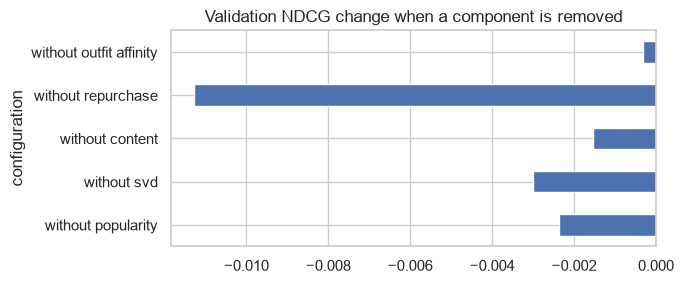

In [12]:
full = ndcg_of(hybrid.recommend(ranks_all, weights_all, users_all, K, gamma=best_gamma_all), val_m, users_all)
rows = [{"configuration": "full hybrid", "NDCG": full, "change vs full": 0.0}]
for name, w in weights_all.items():
    if w > 0 and sum(v > 0 for v in weights_all.values()) > 1:
        reduced = {**weights_all, name: 0.0}
        score = ndcg_of(hybrid.recommend(ranks_all, reduced, users_all, K, gamma=best_gamma_all), val_m, users_all)
        rows.append({"configuration": f"without {name}", "NDCG": score, "change vs full": score - full})
if best_gamma_all > 0:
    score = ndcg_of(hybrid.recommend(ranks_all, weights_all, users_all, K, gamma=0.0), val_m, users_all)
    rows.append({"configuration": "without outfit affinity", "NDCG": score, "change vs full": score - full})
ablation = pd.DataFrame(rows)
display(ablation)
ablation.set_index("configuration")["change vs full"].iloc[1:].plot(kind="barh", figsize=(7, 3), title="Validation NDCG change when a component is removed")
save_fig("hybrid_ablation.png")

## 6. Final evaluation on the test block
Everything is now fixed. The models are refitted on **training plus validation** with the tuned settings and evaluated once on the test block. Test users are those with at least one test purchase; the discovery track counts first-time purchases only.

Rating-prediction metrics (MAE, RMSE) are not used: the data contain purchases, not ratings, so no model predicts a rating.

In [13]:
trainval = pd.concat([exp.split.train, exp.split.val], ignore_index=True)
log_lift_final = hy.log_lift_matrix(trainval, articles, exp.category_names)
final = hy.HybridRecommender(params, exp.users, exp.items, exp.category_of_item, exp.category_names,
                             content_tables[content_choice["cw"]], log_lift_final).fit(trainval)
test_m = exp.test_matrix
test_new = (test_m - test_m.multiply(final.seen)).tocsr()
test_new.eliminate_zeros()
test_users_all, test_users_new = prep.users_with_interactions(test_m), prep.users_with_interactions(test_new)
test_ranks_all, test_ranks_new = final.component_ranks(test_users_all), final.component_ranks(test_users_new)
item_share_final = final.seen.getnnz(axis=0) / final.seen.shape[0]
print(f"test users: all purchases {len(test_users_all):,} | with a first-time purchase {len(test_users_new):,}")

def evaluate_test(recs, truth, users):
    return ev.evaluate_topk(recs, truth, users, item_share_final, N_ITEMS, exp.category_of_item)

def table(ranks, truth, users, models):
    recs = {name: final.recommend(ranks, w, users, K, gamma=g) for name, (w, g) in models.items()}
    return recs, pd.DataFrame({name: evaluate_test(r, truth, users) for name, r in recs.items()}).T

models_all = {
    "popularity (incl. already bought)": ({"popularity_incl_seen": 1.0}, 0.0),
    "repurchase + popularity": ({"repurchase": 1.0}, 0.0),
    "item-item CF": ({"item_knn": 1.0}, 0.0),
    "latent factors (SVD)": ({"svd": 1.0}, 0.0),
    "hybrid": (weights_all, best_gamma_all),
}
models_new = {
    "popularity": ({"popularity": 1.0}, 0.0),
    "item-item CF": ({"item_knn": 1.0}, 0.0),
    "latent factors (SVD)": ({"svd": 1.0}, 0.0),
    "content similarity": ({"content": 1.0}, 0.0),
    "hybrid (discovery)": (weights_new, best_gamma_new),
}
recs_all, results_all = table(test_ranks_all, test_m, test_users_all, models_all)
recs_new, results_new = table(test_ranks_new, test_new, test_users_new, models_new)
print("TRACK 2: all purchases (test)"); display(results_all)
print("TRACK 1: discovery of new items (test)"); display(results_new)

test users: all purchases 5,385 | with a first-time purchase 5,176
TRACK 2: all purchases (test)


,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
popularity (incl. already bought),0.0081,0.0409,0.0215,0.0008,7.6659,0.0082,0.6000,"5,385.0000"
repurchase + popularity,0.0087,0.0481,0.0360,0.8521,8.9056,0.0035,0.6271,"5,385.0000"
item-item CF,0.0053,0.0257,0.0169,0.6919,8.8466,0.0033,0.4108,"5,385.0000"
latent factors (SVD),0.0057,0.0276,0.0183,0.0241,7.6343,0.0068,0.5877,"5,385.0000"
hybrid,0.0107,0.0591,0.0399,0.7898,8.7238,0.0039,0.6027,"5,385.0000"


TRACK 1: discovery of new items (test)


,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
popularity,0.0078,0.0394,0.0202,0.0012,7.7002,0.0080,0.5985,"5,176.0000"
item-item CF,0.0055,0.0291,0.0187,0.6863,8.8485,0.0033,0.4108,"5,176.0000"
latent factors (SVD),0.0059,0.0306,0.0198,0.0238,7.6304,0.0068,0.5878,"5,176.0000"
content similarity,0.0033,0.0182,0.0106,0.7404,9.4227,0.0020,0.2044,"5,176.0000"
hybrid (discovery),0.0088,0.0484,0.0286,0.2691,7.8837,0.0074,0.5776,"5,176.0000"


**Metric guide.** Precision/Recall/NDCG measure whether purchased items appear in the Top-10. *Coverage* is the share of the catalogue that appears in any list; *novelty* is higher when less popular items are recommended; *mean popularity* is the average share of customers who bought the recommended items (popularity bias); *category diversity* is the share of distinct product types per list.

### Is the hybrid's advantage real? Paired bootstrap over users

In [14]:
def ndcg_per_user(recs, truth, users):
    return ev.precision_recall_ndcg(recs, truth[users])["ndcg"].to_numpy()

comparisons = []
for label, recs, truth, users, hyb_name, base_names in [
        ("all purchases", recs_all, test_m, test_users_all, "hybrid", ["popularity (incl. already bought)", "repurchase + popularity", "item-item CF", "latent factors (SVD)"]),
        ("discovery", recs_new, test_new, test_users_new, "hybrid (discovery)", ["popularity", "item-item CF", "latent factors (SVD)", "content similarity"])]:
    hyb_scores = ndcg_per_user(recs[hyb_name], truth, users)
    for base in base_names:
        r = ev.paired_bootstrap(hyb_scores, ndcg_per_user(recs[base], truth, users), config.BOOTSTRAP_SAMPLES, config.RANDOM_SEED)
        comparisons.append({"track": label, "hybrid minus": base, **r})
display(pd.DataFrame(comparisons))

,track,hybrid minus,mean_difference,ci_low,ci_high,significant
0,all purchases,popularity (incl. already bought),0.0184,0.0141,0.0228,True
1,all purchases,repurchase + popularity,0.0038,0.0019,0.0059,True
2,all purchases,item-item CF,0.0229,0.0187,0.0271,True
3,all purchases,latent factors (SVD),0.0216,0.0177,0.0256,True
4,discovery,popularity,0.0085,0.0057,0.0114,True
5,discovery,item-item CF,0.0099,0.0070,0.0130,True
6,discovery,latent factors (SVD),0.0088,0.0065,0.0111,True
7,discovery,content similarity,0.0180,0.0152,0.0208,True


A difference is called significant when its 95% bootstrap interval excludes zero. With a few thousand users and very small absolute NDCG values, treat small differences cautiously and report the interval, not just the point estimate.

## 7. Validation versus test
A large gap between validation (used for tuning) and test would indicate over-tuning, or a shift between the two periods.

In [15]:
val_check = {
    "hybrid (all purchases)": ndcg_of(hybrid.recommend(ranks_all, weights_all, users_all, K, gamma=best_gamma_all), val_m, users_all),
    "hybrid (discovery)": ndcg_of(hybrid.recommend(ranks_new, weights_new, users_new, K, gamma=best_gamma_new), val_new, users_new)}
test_check = {"hybrid (all purchases)": results_all.loc["hybrid", f"NDCG@{K}"],
              "hybrid (discovery)": results_new.loc["hybrid (discovery)", f"NDCG@{K}"]}
display(pd.DataFrame({"validation NDCG": val_check, "test NDCG": test_check}))

,validation NDCG,test NDCG
hybrid (all purchases),0.0349,0.0399
hybrid (discovery),0.0282,0.0286


## 8. Cold-item slice: new arrivals
The main comparison covers items with training history. Purchases of items outside that universe (new or rarely bought) were saved separately. Here a *new-arrivals shelf* is simulated: for customers who bought at least one such item in the test period, rank the pool of items that sold for the first time (or rarely) in that period using content similarity to the customer's recent purchases, and compare with random ranking. No collaborative model can score these items, because they have no purchase history.

In [16]:
cold = prepared.cold_items
test_start = pd.Timestamp(prepared.meta["test_start"])
cold_test = cold[cold["t_dat"] >= test_start]
pool_ids = np.sort(cold_test["article_id"].unique())
print(f"test period: {len(cold_test):,} cold-item purchases ({len(cold_test) / (len(cold_test) + test_m.nnz):.1%} of all purchases by these customers), "
      f"{len(pool_ids):,} distinct cold items")

best_cw = content_choice["cw"]
all_features = hy.build_item_features(articles_by_id.reset_index(), categorical_weight=best_cw)
row_of = articles_by_id.index.get_indexer
F_items, F_pool = all_features[row_of(exp.items)], all_features[row_of(pool_ids)]
users_cold = exp.users.get_indexer(cold_test["customer_id"].cat.categories)[cold_test["customer_id"].cat.codes.to_numpy()]
pool_pos = np.searchsorted(pool_ids, cold_test["article_id"].to_numpy())
truth_cold = sparse.csr_matrix((np.ones(len(users_cold), dtype=np.float32), (users_cold, pool_pos)),
                               shape=(len(exp.users), len(pool_ids)))
truth_cold.data[:] = 1.0
cold_users = np.flatnonzero(truth_cold.getnnz(axis=1) > 0)
profile = final.content_history[cold_users] @ F_items          # only the customers being evaluated
scores = profile @ F_pool.T
scores = scores.toarray() if sparse.issparse(scores) else np.asarray(scores)
kk = min(K, len(pool_ids))
top = np.argsort(-scores, axis=1)[:, :kk]
measured = ev.precision_recall_ndcg(top, truth_cold[cold_users])
rng = np.random.default_rng(config.RANDOM_SEED)
random_top = np.array([rng.choice(len(pool_ids), kk, replace=False) for _ in cold_users])
baseline = ev.precision_recall_ndcg(random_top, truth_cold[cold_users])
display(pd.DataFrame({"content similarity": measured.mean(), "random": baseline.mean()}).T)
print(f"Content similarity recall is {measured['recall'].mean() / max(baseline['recall'].mean(), 1e-12):.1f}x random for {len(cold_users):,} customers")

test period: 16,941 cold-item purchases (58.9% of all purchases by these customers), 4,717 distinct cold items


,precision,recall,ndcg
content similarity,0.0057,0.0252,0.0166
random,0.0005,0.0018,0.0010


Content similarity recall is 14.2x random for 5,928 customers


## 9. Who benefits? Results by customer activity (test, all purchases)

,popularity (incl. already bought),repurchase + popularity,item-item CF,hybrid,customers
<=8 items,0.0214,0.0332,0.0089,0.0348,881
9-15,0.0215,0.0357,0.0243,0.0408,1361
16-30,0.0200,0.0373,0.0154,0.0414,1675
31+,0.0233,0.0365,0.0167,0.0402,1468


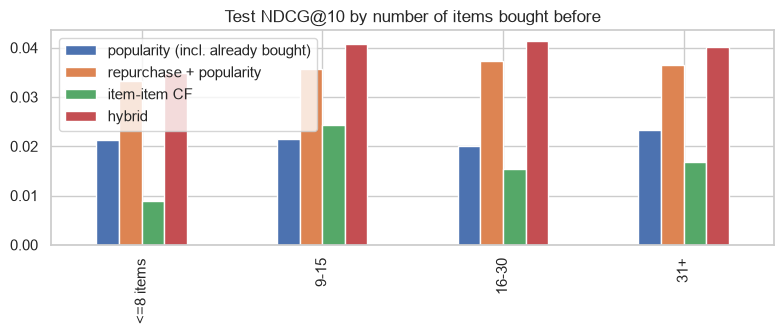

In [17]:
activity = final.seen.getnnz(axis=1)[test_users_all]
bins = pd.cut(activity, [0, 8, 15, 30, np.inf], labels=["<=8 items", "9-15", "16-30", "31+"])
segment = pd.DataFrame({name: pd.Series(ndcg_per_user(recs_all[name], test_m, test_users_all)).groupby(bins, observed=True).mean()
                        for name in ["popularity (incl. already bought)", "repurchase + popularity", "item-item CF", "hybrid"]})
segment["customers"] = pd.Series(bins).value_counts().reindex(segment.index)
display(segment)
segment.drop(columns="customers").plot(kind="bar", figsize=(8, 3.5), title=f"Test NDCG@{K} by number of items bought before")
save_fig("hybrid_by_activity.png")

## 10. Example recommendations with reasons
Each recommendation carries the component that contributed most to it, which is the explanation the Week 5 prototype will show.

In [18]:
rng = np.random.default_rng(config.RANDOM_SEED)
example_rows = rng.choice(len(test_users_all), 5, replace=False)
names = exp.item_names
label = hy.COMPONENT_LABELS
for r in example_rows:
    u = test_users_all[r]
    bought = trainval[trainval["customer_id"] == exp.users[u]].sort_values("t_dat").tail(4)["article_id"]
    print("=" * 100)
    print(f"Customer {str(exp.users[u])[:8]} | {int(final.seen[u].nnz)} distinct items before the test period")
    print("  recently bought:", "; ".join(names[exp.items.get_indexer(bought)]))
    for item in recs_all["hybrid"][r]:
        contrib = hy.component_contributions(test_ranks_all, weights_all, r, item)
        top_component = max(contrib, key=contrib.get) if contrib else "popularity"
        reason = label[top_component]
        if top_component == "item_knn":
            why = final.knn.explain(final.knn_history, u, item, top=1)
            if why:
                reason += f" (because you bought {names[why[0][0]]})"
        hit = " <-- bought in test" if test_m[u, item] > 0 else ""
        print(f"    - {names[item]}  [{reason}]{hit}")

Customer c582cd81 | 8 distinct items before the test period
  recently bought: Tora dress; Oui dress; Babette 2-pack; Mama Support 70 den 1p Tights
    - Mama Support 70 den 1p Tights  [you bought this before]
    - STYLO SLIM SHIRT  [you bought this before]
    - NT Alva 2-pack(1)  [you bought this before]
    - MAMA Hawaii Swimsuit  [you bought this before]
    - Oui dress  [you bought this before]
    - Babette 2-pack  [you bought this before]
    - Tora dress  [you bought this before]
    - Amelie  [trending right now]
    - Romeo dress  [you bought this before]
    - Long leggings update  [matches your taste profile]
Customer 6f019687 | 22 distinct items before the test period
  recently bought: Elsa PQ espadrille; Valentin skirt; Riviera L/S; Henri
    - Henri  [you bought this before]
    - Riviera L/S  [you bought this before]
    - Valentin skirt  [you bought this before]
    - Lucy blouse  [matches your taste profile]
    - Malina  [you bought this before]
    - MUSHROOM SLIM

## 11. Save the results and the final model for Week 5

In [19]:
config.DOCS_DIR.mkdir(exist_ok=True)
pd.concat({"all purchases": results_all, "discovery": results_new}).to_csv(config.DOCS_DIR / "model_comparison_test.csv")
final_settings = {
    "params": params.__dict__, "weights_all_purchases": weights_all, "weights_discovery": weights_new,
    "outfit_gamma_all_purchases": best_gamma_all, "outfit_gamma_discovery": best_gamma_new,
    "content_categorical_weight": content_choice["cw"], "top_k": K,
    "prepared_meta": prepared.meta,
}
(config.DOCS_DIR / "final_model_settings.json").write_text(json.dumps(final_settings, indent=2, default=str))
with open(config.CLEANED_DIR / "final_hybrid.pkl", "wb") as f:
    pickle.dump({"model": final, "settings": final_settings}, f)
print("Saved docs/model_comparison_test.csv, docs/final_model_settings.json and data/cleaned/final_hybrid.pkl")

Saved docs/model_comparison_test.csv, docs/final_model_settings.json and data/cleaned/final_hybrid.pkl


## 12. Findings to write up in your own words
1. **What customers buy next (section 2) and what that implies for the design:** ...
2. **Tuning outcomes for CF, SVD, content and repurchase, and any grid-edge values:** ...
3. **Which components carry the hybrid (weights and ablation) and which add nothing:** ...
4. **Test results on both tracks, with the bootstrap intervals, against the best baseline:** ...
5. **Accuracy versus beyond-accuracy trade-offs (coverage, novelty, popularity bias, diversity):** ...
6. **Does the outfit affinity help? Report the honest answer from the gamma table and ablation:** ...
7. **Cold-start: size of the cold-item share and what the content slice shows:** ...
8. **Validation-versus-test gap, and limitations (single split, short test window, sampled customers, purchases not preferences):** ...
9. **Final model choice and the reason it is the best fit for this problem:** ...